In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    auc
)

In [40]:
train_data = fetch_20newsgroups(
    subset = "train",
    remove = ("headers", "footers", "quotes")
)

In [41]:
test_data = fetch_20newsgroups(
    subset = "test",
    remove = ("headers", "footers", "quotes")
)

In [42]:
X_train_text = train_data.data
y_train = train_data.target

X_test_text = test_data.data
y_test = test_data.target

class_names = train_data.target_names

In [43]:
print("Training documents:",len(X_train_text))
print("Testing documents:",len(X_test_text))
print("Number of classes:",len(class_names))

Training documents: 11314
Testing documents: 7532
Number of classes: 20


In [44]:
vectorizer = CountVectorizer(
    stop_words = "english",
    min_df = 2
)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

In [45]:
print("Training feature matrix:",X_train.shape)
print("Testing feature matrix:",X_test.shape)

Training feature matrix: (11314, 39115)
Testing feature matrix: (7532, 39115)


In [46]:
mnb = MultinomialNB()

mnb.fit(
    X_train,
    y_train
)

y_pred_mnb = mnb.predict(X_test)

In [47]:
binary_vectorizer = CountVectorizer(
    stop_words = "english",
    min_df = 2,
    binary = True
)
X_train_binary = binary_vectorizer.fit_transform(
    X_train_text
)
X_test_binary = binary_vectorizer.transform(
    X_test_text
)

In [48]:
bnb = BernoulliNB()

bnb.fit(
    X_train_binary,
    y_train
)

y_pred_bnb = bnb.predict(
    X_test_binary
)

In [49]:
mnb_accuracy = accuracy_score(y_test, y_pred_mnb)
mnb_precision = precision_score(y_test, y_pred_mnb, average="weighted")
mnb_recall = recall_score(y_test, y_pred_mnb, average="weighted")
mnb_f1 = f1_score(y_test, y_pred_mnb, average="weighted")

bnb_accuracy = accuracy_score(y_test, y_pred_bnb)
bnb_precision = precision_score(y_test, y_pred_bnb, average="weighted")
bnb_recall = recall_score(y_test, y_pred_bnb, average="weighted")
bnb_f1 = f1_score(y_test, y_pred_bnb, average="weighted")


In [50]:
results = pd.DataFrame(columns=[
    "Model",
    "Accuracy",
    "Precision",
    "F1 Score",
    "Recall",
])

models = [
    ("MNB",mnb, y_pred_mnb),
    ("BNB",bnb, y_pred_bnb)
]
for name,model,pred in models:

    results.loc[len(results)] = [
        name,
        accuracy_score(y_test,pred),
        precision_score(y_test,pred,average = 'weighted'),
        recall_score(y_test,pred,average = 'weighted'),
        f1_score(y_test,pred,average = 'weighted')
    ]

print(results)

  Model  Accuracy  Precision  F1 Score    Recall
0   MNB  0.651089   0.642532  0.651089  0.629644
1   BNB  0.485130   0.627034  0.485130  0.480839


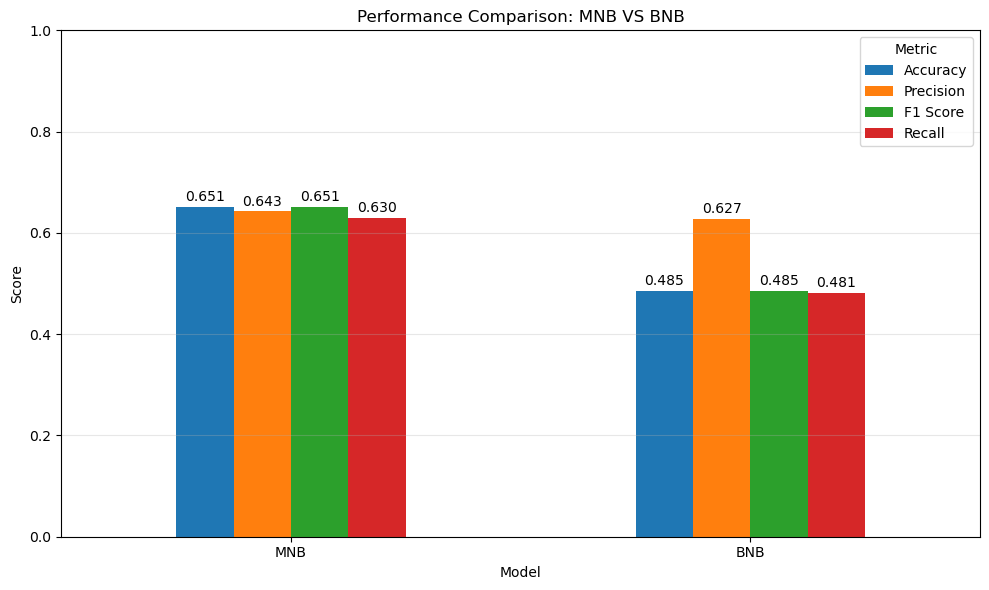

In [51]:
ax = results.set_index("Model").plot(
    kind = "bar",
    figsize=(10,6)
)

plt.title("Performance Comparison: MNB VS BNB")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation = 0)
plt.legend(title = "Metric")
plt.grid(axis = "y", alpha = 0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f",padding=2)

plt.tight_layout()
plt.show()

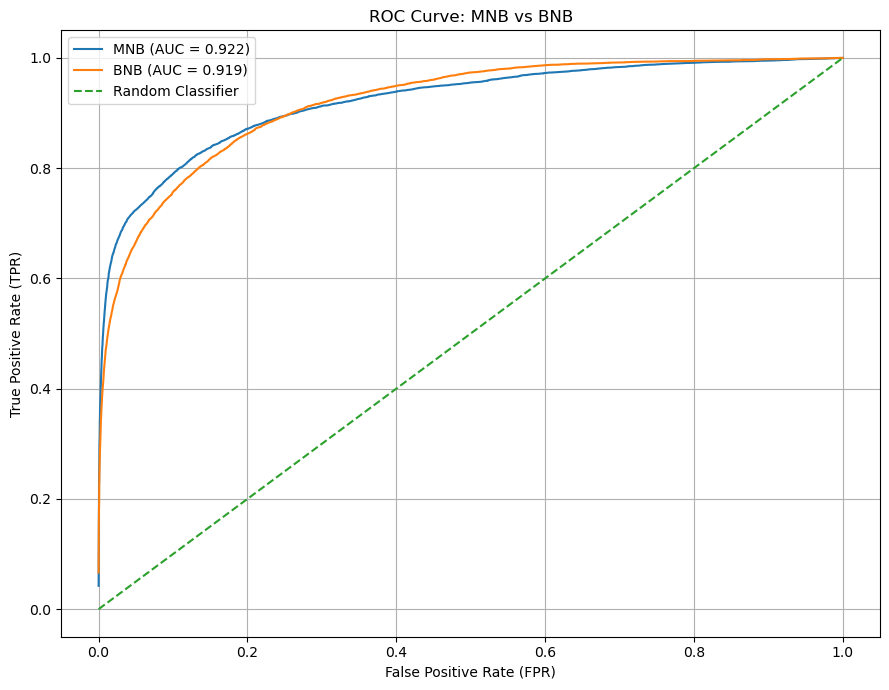

In [52]:
plt.figure(figsize=(9,7))

# Convert multiclass y_test into binary format
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(class_names))
)

for name, model, pred in models:
    
    # Use the correct feature matrix for each model
    if name == "MNB":
        X = X_test
    else:
        X = X_test_binary
    
    # Predicted probabilities for all 20 classes
    y_prob = model.predict_proba(X)

    # Store ROC values for each class
    fpr = {}
    tpr = {}

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(
            y_test_bin[:, i],
            y_prob[:, i]
        )

    # Calculate macro-average ROC curve
    all_fpr = np.unique(
        np.concatenate(
            [fpr[i] for i in range(len(class_names))]
        )
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(len(class_names)):
        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= len(class_names)

    roc_auc = auc(all_fpr, mean_tpr)

    plt.plot(
        all_fpr,
        mean_tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve: MNB vs BNB")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
